# Project 2 - Concrete Compressive Strength Prediction

This notebook follows: data understanding => justified preparation => mean-prediction baseline =>
linear-vs-non-linear comparison with residual diagnostics => a direct discussion of whether a
predictive cement-strength association licenses a causal, "change the mix" claim.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)


## 1. Data Loading


In [2]:
df = pd.read_csv("data/Concrete_Data.csv")
print("Shape:", df.shape)
df.head()


Shape: (1030, 9)


,Cement (kg in a m^3 mixture),Blast Furnace Slag (kg in a m^3 mixture),Fly Ash (kg in a m^3 mixture),Water (kg in a m^3 mixture),Superplasticizer (kg in a m^3 mixture),Coarse Aggregate (kg in a m^3 mixture),Fine Aggregate (kg in a m^3 mixture),Age (day),"Concrete compressive strength (MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [3]:
# Original column names are long UCI-style labels; rename to short, code-friendly names.
# (Units preserved in this mapping for reference.)
COLUMN_RENAME = {
    df.columns[0]: "cement",            # kg/m^3
    df.columns[1]: "slag",              # kg/m^3 (blast furnace slag)
    df.columns[2]: "fly_ash",           # kg/m^3
    df.columns[3]: "water",             # kg/m^3
    df.columns[4]: "superplasticizer",  # kg/m^3
    df.columns[5]: "coarse_agg",        # kg/m^3
    df.columns[6]: "fine_agg",          # kg/m^3
    df.columns[7]: "age",               # days
    df.columns[8]: "strength",          # MPa (target)
}
df = df.rename(columns=COLUMN_RENAME)
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   cement            1030 non-null   float64
 1   slag              1030 non-null   float64
 2   fly_ash           1030 non-null   float64
 3   water             1030 non-null   float64
 4   superplasticizer  1030 non-null   float64
 5   coarse_agg        1030 non-null   float64
 6   fine_agg          1030 non-null   float64
 7   age               1030 non-null   int64  
 8   strength          1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


## 2. Exploratory Data Analysis & Data Report

### 2.1 Missing values and duplicates


In [4]:
print("Missing values per column:")
print(df.isna().sum())

n_dupes = df.duplicated().sum()
print(f"\nExact duplicate rows: {n_dupes}")
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after de-duplication:", df.shape)


Missing values per column:
cement              0
slag                0
fly_ash             0
water               0
superplasticizer    0
coarse_agg          0
fine_agg            0
age                 0
strength            0
dtype: int64

Exact duplicate rows: 25
Shape after de-duplication: (1005, 9)


No missing values. 25 exact duplicate rows are present so we drop them to avoid letting identical points count multiple times in both training and evaluation.

### 2.2 Feature distributions


In [5]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
cement,1005.0,278.629055,104.345003,102.000000,190.680000,265.000000,349.00000,540.000000
slag,1005.0,72.043134,86.170555,0.000000,0.000000,20.000000,142.50000,359.400000
fly_ash,1005.0,55.535075,64.207448,0.000000,0.000000,0.000000,118.27000,200.100000
water,1005.0,182.074378,21.340740,121.750000,166.610000,185.700000,192.94000,247.000000
superplasticizer,1005.0,6.031647,5.919559,0.000000,0.000000,6.100000,10.00000,32.200000
coarse_agg,1005.0,974.376468,77.579534,801.000000,932.000000,968.000000,1031.00000,1145.000000
fine_agg,1005.0,772.686617,80.339851,594.000000,724.300000,780.000000,822.20000,992.600000
age,1005.0,45.856716,63.734692,1.000000,7.000000,28.000000,56.00000,365.000000
strength,1005.0,35.250273,16.284808,2.331808,23.523542,33.798114,44.86834,82.599225


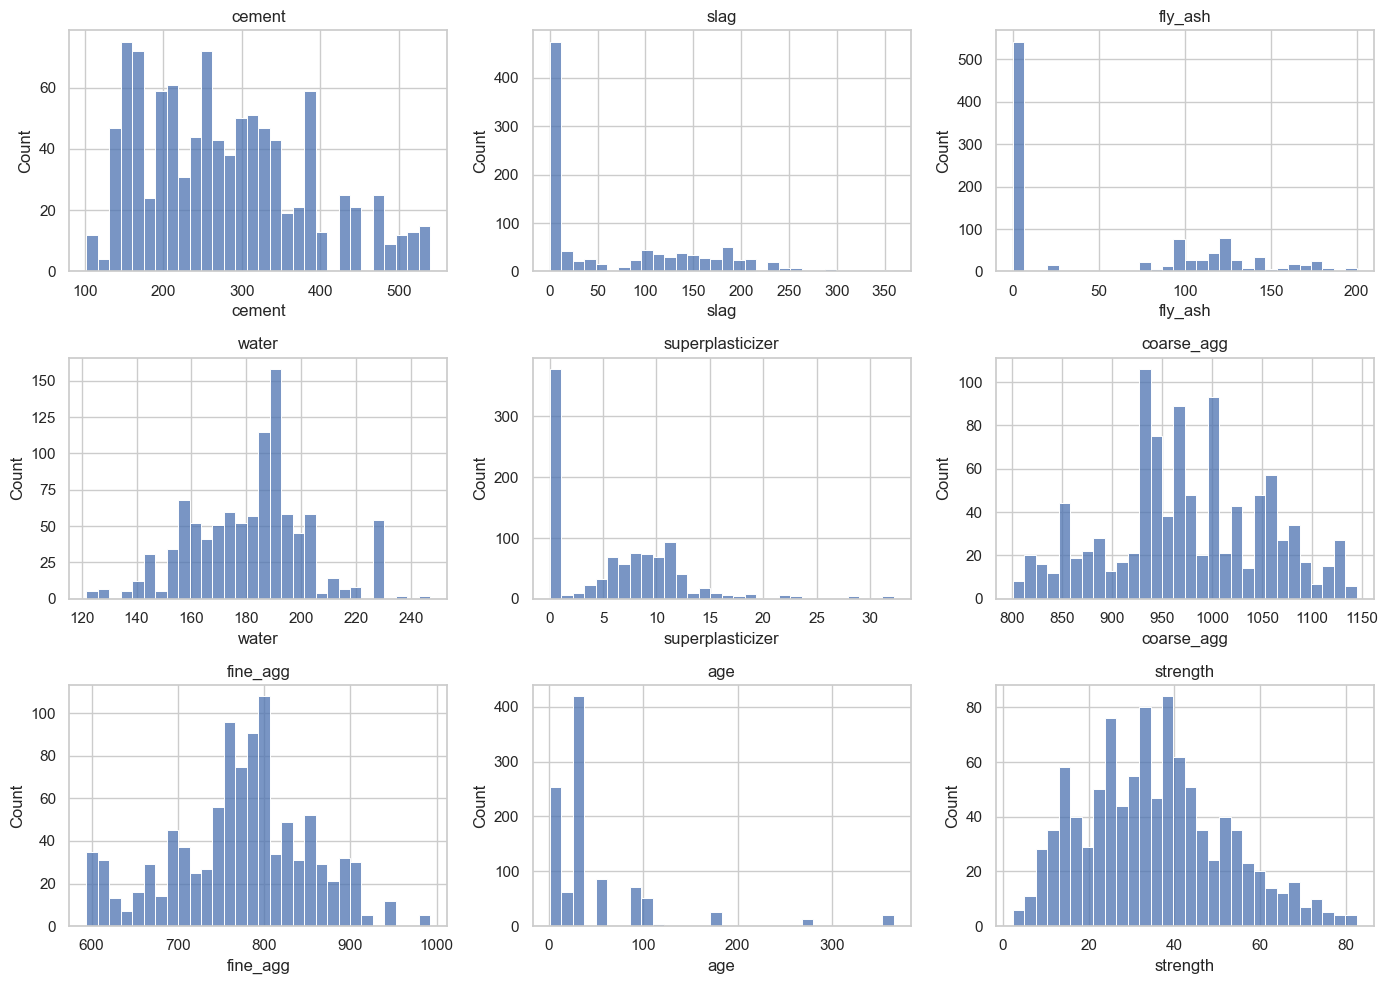

In [6]:
feature_cols = ["cement", "slag", "fly_ash", "water", "superplasticizer",
                 "coarse_agg", "fine_agg", "age", "strength"]
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.ravel(), feature_cols):
    sns.histplot(df[col], bins=30, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()


**Key observations:**
- `age` is extremely right-skewed (standard testing ages: 1, 3, 7, 14, 28, 56, 90, 180, 365
  days), with a long tail out to 365 days.
- `slag`, `fly_ash`, and `superplasticizer` each have a large spike at/near 0. Many mixes don't use that ingredient. This is a genuine feature of the mix-design data, not missingness, so we leave these values as-is (0 is meaningful: "not used").
- `cement`, `water`, `coarse_agg`, `fine_agg` are roughly unimodal/mildly skewed with no obvious
  data-entry errors.

### 2.3 Correlation structure and multicollinearity


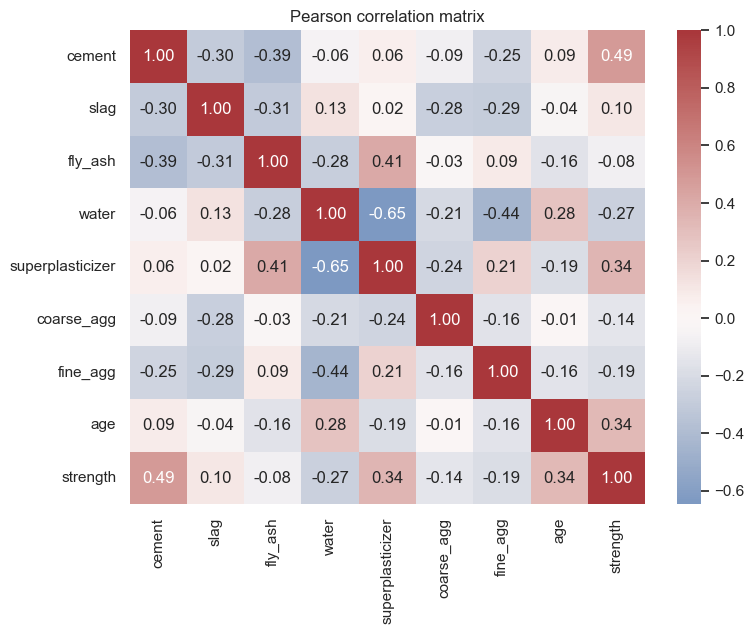

In [7]:
corr = df[feature_cols].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Pearson correlation matrix")
plt.tight_layout()
plt.show()


In [8]:
# Variance Inflation Factor on the raw (unstandardized) predictors — VIF is scale-invariant.
X_vif = df[feature_cols[:-1]]
vif = pd.DataFrame({
    "feature": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])],
}).sort_values("VIF", ascending=False)
vif


,feature,VIF
5,coarse_agg,84.738626
3,water,81.395278
6,fine_agg,72.495779
0,cement,15.155077
4,superplasticizer,5.171809
2,fly_ash,4.171453
1,slag,3.261879
7,age,1.696228


### 2.4 Target relationship with cement and age


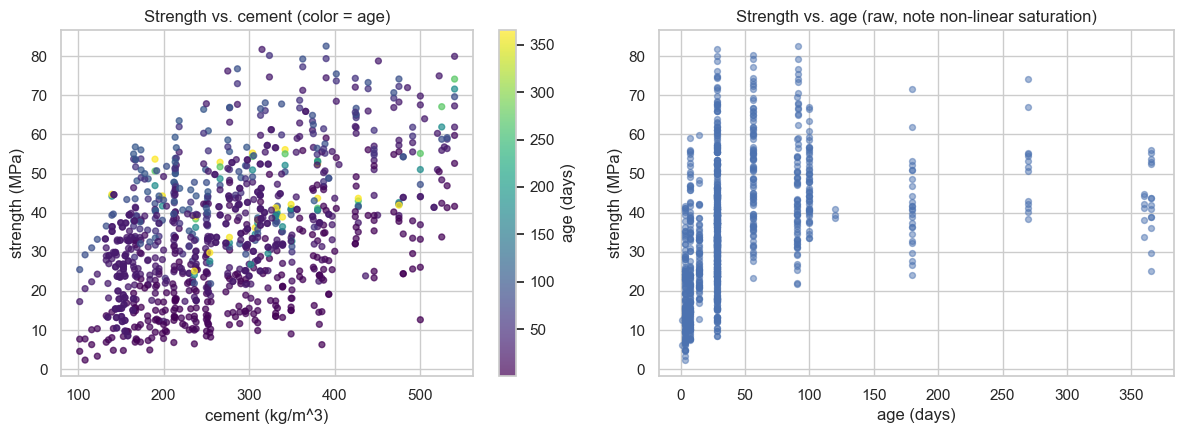

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sc = axes[0].scatter(df["cement"], df["strength"], c=df["age"], cmap="viridis", alpha=0.7, s=18)
axes[0].set_xlabel("cement (kg/m^3)")
axes[0].set_ylabel("strength (MPa)")
axes[0].set_title("Strength vs. cement (color = age)")
plt.colorbar(sc, ax=axes[0], label="age (days)")

axes[1].scatter(df["age"], df["strength"], alpha=0.5, s=18, color="#4C72B0")
axes[1].set_xlabel("age (days)")
axes[1].set_ylabel("strength (MPa)")
axes[1].set_title("Strength vs. age (raw, note non-linear saturation)")
plt.tight_layout()
plt.show()


Strength rises with cement content but with visibly large scatter driven by other ingredients
and age (color gradient on the left). The age-strength scatter (right) shows the classic
decelerating/saturating shape — rapid early gain, flattening after ~28-90 days — the clearest
visual evidence in this dataset for a non-linear modeling approach.


## 3. Data Preparation

Steps applied:

1. **Drop 25 duplicate rows** - avoids double-counting identical records across train/test.
2. **No imputation needed** - zero missing values confirmed.
3. **Keep ingredient zeros as zeros** - a 0 kg/m³ entry for `slag`/`fly_ash`/`superplasticizer`
   is a legitimate "not used in this mix" value, not a missing value; imputing it would
   misrepresent the mix design.
4. **No log-transform of `age` applied to the raw features** — we instead let the *non-linear*
   models (Random Forest, Hist Gradient Boosting) learn the age-strength curve directly from
   splits, and keep the *linear* models on raw `age`.
5. **Plain 80/20 train/test split** (no stratification needed for a continuous target) plus
   **5-fold CV** on the training set for model comparison; `StandardScaler` applied only inside
   the linear-model pipelines (tree ensembles do not need it).


In [10]:
TARGET = "strength"
X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print("Train shape:", X_train.shape, " Test shape:", X_test.shape)


Train shape: (804, 8)  Test shape: (201, 8)


## 4. Mean-Prediction Baseline

`DummyRegressor(strategy="mean")` predicts the training-set mean strength for every test row. Every real model below must clear this floor.


In [11]:
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

baseline_rmse = mean_squared_error(y_test, baseline_pred) ** 0.5
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_r2 = r2_score(y_test, baseline_pred)

print(f"Baseline RMSE: {baseline_rmse:.3f} MPa")
print(f"Baseline MAE:  {baseline_mae:.3f} MPa")
print(f"Baseline R^2:  {baseline_r2:.4f}")


Baseline RMSE: 17.297 MPa
Baseline MAE:  13.972 MPa
Baseline R^2:  -0.0028


As expected, R² is essentially 0 (a mean predictor explains none of the variance by construction) with an RMSE/MAE on the order of the target's own standard deviation. Any model below should substantially beat this.


## 5. Linear vs. Non-Linear Model Comparison

We compare two linear approaches and two non-linear approaches, all evaluated with identical
**5-fold CV** on the training set (RMSE, MAE, R²):

| Model | Family | Why included |
|---|---|---|
| **Linear Regression** | Linear | Simplest interpretable baseline model. |
| **Ridge** (`alpha=1.0`) | Linear, regularized | Addresses the multicollinearity found in §2.3 (water/aggregates) by shrinking unstable coefficients. |
| **Random Forest** | Non-linear (bagged trees) | Can learn the non-linear age-strength curve and ingredient interactions seen in §2.4 without manual transforms. |
| **Hist Gradient Boosting** | Non-linear (boosted trees) | Typically the strongest tabular learner; our primary non-linear candidate. |


In [12]:
models = {
    "Linear Regression": Pipeline([("scale", StandardScaler()), ("reg", LinearRegression())]),
    "Ridge": Pipeline([("scale", StandardScaler()), ("reg", Ridge(alpha=1.0, random_state=RANDOM_STATE))]),
    "Random Forest": Pipeline([("reg", RandomForestRegressor(
        n_estimators=400, random_state=RANDOM_STATE, n_jobs=-1))]),
    "Hist Gradient Boosting": Pipeline([("reg", HistGradientBoostingRegressor(
        random_state=RANDOM_STATE))]),
}

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}

cv_results = {}
for name, pipe in models.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_results[name] = res
    print(f"{name:24s} RMSE {-res['test_rmse'].mean():.3f} +/- {res['test_rmse'].std():.3f}"
          f"   MAE {-res['test_mae'].mean():.3f}   R2 {res['test_r2'].mean():.4f}")


Linear Regression        RMSE 10.203 +/- 0.153   MAE 8.100   R2 0.5895
Ridge                    RMSE 10.203 +/- 0.152   MAE 8.109   R2 0.5895
Random Forest            RMSE 5.363 +/- 0.504   MAE 3.879   R2 0.8857
Hist Gradient Boosting   RMSE 4.827 +/- 0.268   MAE 3.355   R2 0.9082


In [13]:
cv_summary = pd.DataFrame({
    name: {
        "RMSE mean": -res["test_rmse"].mean(),
        "RMSE std": res["test_rmse"].std(),
        "MAE mean": -res["test_mae"].mean(),
        "R2 mean": res["test_r2"].mean(),
    }
    for name, res in cv_results.items()
}).T.sort_values("RMSE mean")
cv_summary


,RMSE mean,RMSE std,MAE mean,R2 mean
Hist Gradient Boosting,4.826877,0.267952,3.355003,0.908156
Random Forest,5.363157,0.503622,3.878823,0.885691
Ridge,10.202612,0.152410,8.108774,0.589468
Linear Regression,10.202737,0.153498,8.100291,0.589460


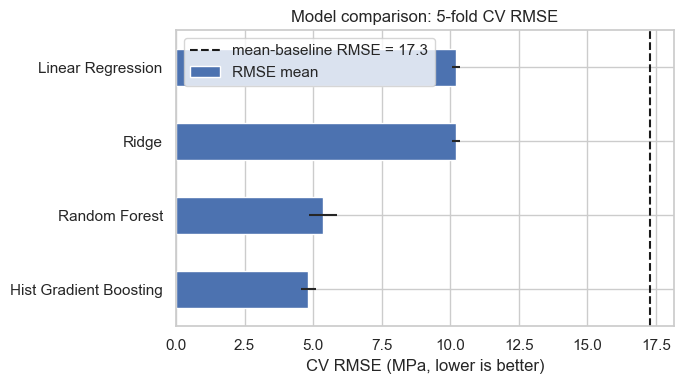

In [14]:
fig, ax = plt.subplots(figsize=(7, 4))
cv_summary["RMSE mean"].plot(kind="barh", xerr=cv_summary["RMSE std"], color="#4C72B0", ax=ax)
ax.axvline(baseline_rmse, color="k", linestyle="--", label=f"mean-baseline RMSE = {baseline_rmse:.1f}")
ax.set_xlabel("CV RMSE (MPa, lower is better)")
ax.set_title("Model comparison: 5-fold CV RMSE")
ax.legend()
plt.tight_layout()
plt.show()


**Finding:** the non-linear models (Random Forest, Hist Gradient Boosting) cut CV RMSE roughly
in half compared to the linear models, and raise R² from ~0.6 to ~0.85-0.9. Ridge performs
almost identically to plain Linear Regression. Regularization alone does not fix the
*functional-form* mismatch (linear vs. the true non-linear age/ingredient relationships); it
only stabilizes coefficients under multicollinearity. This directly confirms the non-linearity
flagged in section 2.4: a linear model is the wrong function class for this problem, not just
under-regularized.



In [15]:
lin_model = models["Linear Regression"].fit(X_train, y_train)
best_model = models["Hist Gradient Boosting"].fit(X_train, y_train)

lin_pred = lin_model.predict(X_test)
best_pred = best_model.predict(X_test)

for name, pred in [("Linear Regression", lin_pred), ("Hist Gradient Boosting", best_pred)]:
    rmse = mean_squared_error(y_test, pred) ** 0.5
    mae = mean_absolute_error(y_test, pred)
    r2 = r2_score(y_test, pred)
    print(f"{name:24s} TEST RMSE {rmse:.3f}  MAE {mae:.3f}  R2 {r2:.4f}")


Linear Regression        TEST RMSE 11.192  MAE 8.896  R2 0.5801
Hist Gradient Boosting   TEST RMSE 4.553  MAE 3.047  R2 0.9305


## 6. Residual Diagnostics.

### 6.1 Residuals vs. fitted values


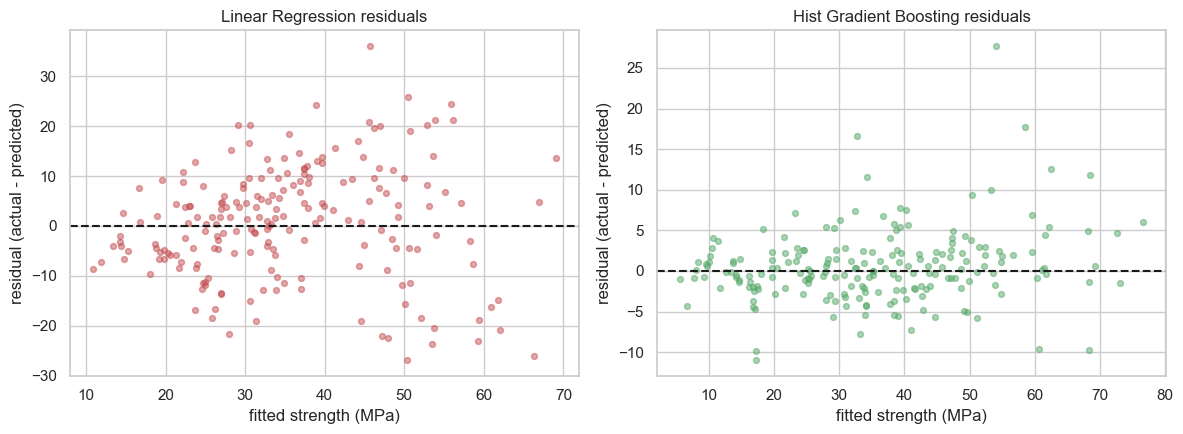

In [21]:
residual_lin = y_test.values - lin_pred
residual_best = y_test.values - best_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(lin_pred, residual_lin, alpha=0.5, s=18, color="#C44E52")
axes[0].axhline(0, color="k", linestyle="--")
axes[0].set_xlabel("fitted strength (MPa)")
axes[0].set_ylabel("residual (actual - predicted)")
axes[0].set_title("Linear Regression residuals")

axes[1].scatter(best_pred, residual_best, alpha=0.5, s=18, color="#55A868")
axes[1].axhline(0, color="k", linestyle="--")
axes[1].set_xlabel("fitted strength (MPa)")
axes[1].set_ylabel("residual (actual - predicted)")
axes[1].set_title("Hist Gradient Boosting residuals")
plt.tight_layout()
plt.show()


The Linear Regression residuals show a visible bow/curvature pattern across the fitted range which is the classic signature of a misspecified functional form. The Hist Gradient Boosting residuals scatter much more tightly and evenly around zero, with no obvious remaining structure.

### 6.2 Residuals vs. age and water (where the linear model struggles most)


In [22]:
age_bins = pd.cut(X_test["age"], bins=[0, 7, 28, 90, 400],
                   labels=["<=7d", "8-28d", "29-90d", ">90d"])
water_quartile = pd.qcut(X_test["water"], 4)

diag = pd.DataFrame({
    "age_bin": age_bins.values,
    "water_quartile": water_quartile.values,
    "abs_err_linear": np.abs(residual_lin),
    "abs_err_hgb": np.abs(residual_best),
    "signed_err_linear": residual_lin,
})

print("Mean absolute error by age bin:")
print(diag.groupby("age_bin", observed=True)[["abs_err_linear", "abs_err_hgb"]].mean())
print()
print("Mean SIGNED error (Linear Regression) by age bin -- bias direction:")
print(diag.groupby("age_bin", observed=True)["signed_err_linear"].mean())
print()
print("Mean absolute error by water quartile:")
print(diag.groupby("water_quartile", observed=True)[["abs_err_linear", "abs_err_hgb"]].mean())


Mean absolute error by age bin:
         abs_err_linear  abs_err_hgb
age_bin                             
<=7d          10.544466     2.781625
8-28d          7.274534     3.402841
29-90d         9.198625     2.838451
>90d          10.407418     2.660884

Mean SIGNED error (Linear Regression) by age bin -- bias direction:
age_bin
<=7d     -10.405585
8-28d      4.571059
29-90d     9.198625
>90d       2.356455
Name: signed_err_linear, dtype: float64

Mean absolute error by water quartile:
                  abs_err_linear  abs_err_hgb
water_quartile                               
(126.999, 168.0]       12.984875     4.241902
(168.0, 185.7]          7.999272     2.907570
(185.7, 192.94]         7.537473     2.814189
(192.94, 247.0]         6.897591     2.183246


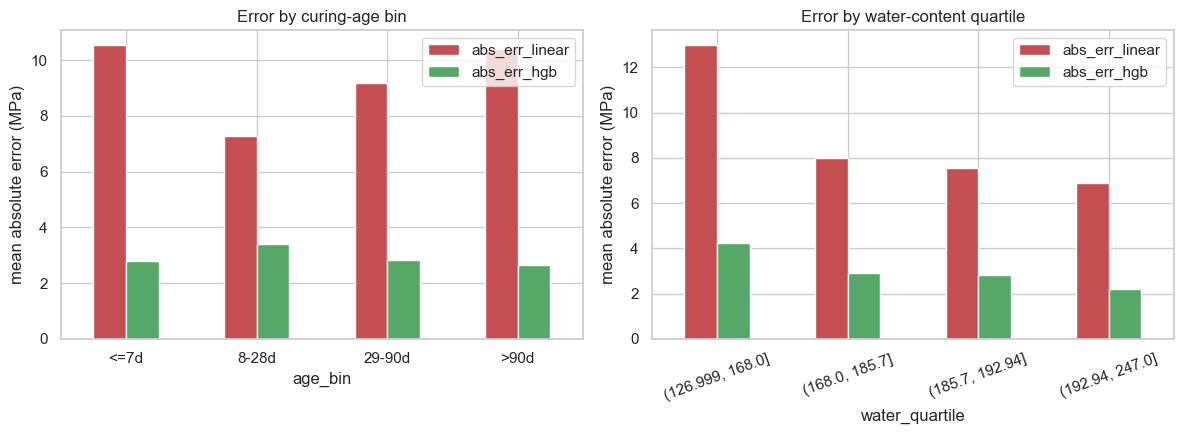

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
diag.groupby("age_bin", observed=True)[["abs_err_linear", "abs_err_hgb"]].mean().plot(
    kind="bar", ax=axes[0], color=["#C44E52", "#55A868"])
axes[0].set_ylabel("mean absolute error (MPa)")
axes[0].set_title("Error by curing-age bin")
axes[0].tick_params(axis="x", rotation=0)

diag.groupby("water_quartile", observed=True)[["abs_err_linear", "abs_err_hgb"]].mean().plot(
    kind="bar", ax=axes[1], color=["#C44E52", "#55A868"])
axes[1].set_ylabel("mean absolute error (MPa)")
axes[1].set_title("Error by water-content quartile")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()


**Evidence of where predictions are weakest:** the Linear Regression model's mean *absolute*
error is highest at the two **age extremes** -- very young concrete (<=7 days) and old concrete
(>90 days) -- and lowest in the 8-28 day range. The *signed*-error breakdown explains why: at
<=7 days the mean signed error is strongly **negative** (the model systematically
*over*-predicts -- real early-age strength is still low, but the straight-line fit, anchored to
the bulk of the data at older ages, overshoots it); at 29-90 days the mean signed error is
strongly **positive**, its largest magnitude (the model *under*-predicts -- this is the steep,
concave part of the true age-strength curve, which a straight line cannot track); by >90 days the
bias shrinks again as the curve flattens and the data's dominant linear trend is a closer local
fit. This is the textbook signature of fitting a straight line to a concave/saturating
relationship: the fitted line cuts through the curve, overshooting at one end and undershooting
in the middle. Hist Gradient Boosting's absolute error is both far smaller (roughly a third of
the linear model's) and much flatter across every age bin, confirming it correctly captures this
curvature end-to-end. A smaller, consistent gap also appears across water-content quartiles
(linear error shrinks as water content rises, non-linear error stays comparatively low and
flat throughout), consistent with the water/aggregate multicollinearity noted in §2.3 making
the linear model's handling of water content less reliable. In short: **the linear model is
weakest for very young and very old concrete and in the water-content tails**, while Hist
Gradient Boosting stays accurate and stable across the full range tested.


## 7. Does Predictive Cement-Strength Association Prove a Causal, "Change-the-Mix" Effect?

**No. association in this dataset does not, by itself, establish that increasing cement in a
real mix will increase strength by the model's estimated amount.** Reasons:

1. **Observational, not experimental, data.** These 1,005 mixes were not sampled by randomly assigning cement content while holding everything else fixed; they are real-world mix designs where engineers choose ingredient quantities together, informed by the water-cement ratio and strength targets. Cement content is therefore **confounded** with water, aggregates, and admixture choices.

2. **What the model captures is correlation within the observed design space.** A feature-
   importance or partial-dependence curve for `cement` shows how predicted
   strength co-varies with cement *holding the model's other learned patterns fixed*, which is
   not the same as a controlled physical experiment that varies cement while literally holding
   water, aggregates, and curing conditions constant.


**Conclusion:** the predictive association is suggestive and consistent with established engineering theory, but confirming the real-world causal effect of changing cement content requires either (a) a controlled experiment that varies cement while holding other ingredients and curing conditions fixed, or (b) explicit causal modeling, not a correlational fit on observational mix data.

### Supporting evidence: cement's partial-dependence relationship in the fitted model


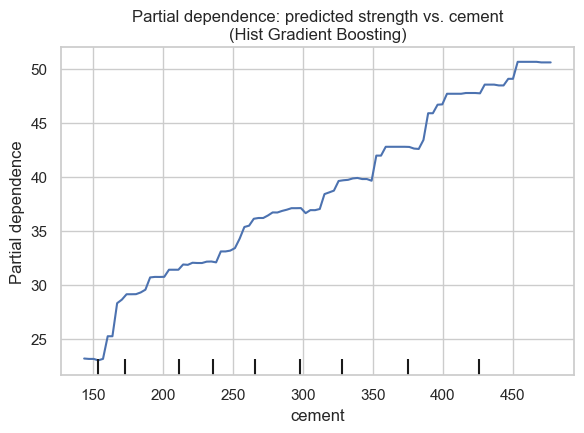

In [19]:
fig, ax = plt.subplots(figsize=(6, 4.5))
PartialDependenceDisplay.from_estimator(best_model, X_train, features=["cement"], ax=ax)
ax.set_title("Partial dependence: predicted strength vs. cement\n(Hist Gradient Boosting)")
plt.tight_layout()
plt.show()


In [20]:
perm_importance = permutation_importance(
    best_model, X_test, y_test, n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1
)
importance_df = pd.DataFrame({
    "feature": X.columns,
    "importance_mean": perm_importance.importances_mean,
    "importance_std": perm_importance.importances_std,
}).sort_values("importance_mean", ascending=False)
importance_df


,feature,importance_mean,importance_std
7,age,0.735034,0.057838
0,cement,0.551153,0.060717
3,water,0.178967,0.013969
1,slag,0.137575,0.017175
4,superplasticizer,0.097074,0.010986
6,fine_agg,0.061023,0.006289
5,coarse_agg,0.020264,0.002514
2,fly_ash,0.005446,0.001576


## 8. Summary

- **Baseline:** mean-prediction - R² ≈ 0 by construction.
- **Best model:** Hist Gradient Boosting, roughly halving CV RMSE versus Linear
  Regression/Ridge and lifting R² from the ~0.6 linear range into the ~0.85-0.9+ range.
- **Why non-linear wins:** the age-strength relationship saturates, and water/aggregate multicollinearity further destabilizes linear coefficients; Ridge regularization does not close the gap, confirming the issue is functional form, not just variance.
- **Weakest region:** Linear Regression is least accurate at the age extremes. It over-predicts strength for very young concrete (<=7 days) and under-predicts most strongly in the 29-90 day range, the steep part of the true age-strength curve; Hist Gradient Boosting stays accurate and flat across all age bins.
- **Causality:** a strong cement-strength association in this model is not proof that changing cement content causally changes real-world strength by the fitted amount.
